# Práctica 4 Procesamiento geométrico y procesamiento de histograma

## Universidad Autónoma de Nuevo León
## Facultad de Ingeniería Mecánica y Eléctrica

Integrantes:
- Cristian Alexis De La Cruz Cabrera 2065212
- Octavio Rodríguez Cázares 2100243

Grupo: 309
Hora: N4 / Día: Miércoles

Docence : Ing. Noe Adiel Ponce Moreno


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from google.colab import files

# Configuración de las figuras
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "font.size": 11,
    "axes.titlesize": 12
})

# Archivos que utilizaremos
NOMBRE_GEOMETRIA = "imagen 2.jpg"
NOMBRE_HISTOGRAMA = "Imagen 1.jpg"

carpeta_resultados = Path("resultados_practica_4")
carpeta_resultados.mkdir(exist_ok=True)


def buscar_archivo(nombre):
    for ruta in Path(".").iterdir():
        if ruta.is_file() and ruta.name.lower() == nombre.lower():
            return ruta
    return None


nombres = [NOMBRE_GEOMETRIA, NOMBRE_HISTOGRAMA]

faltantes = [
    nombre for nombre in nombres
    if buscar_archivo(nombre) is None
]

if faltantes:
    print("Selecciona las siguientes imágenes:")
    for nombre in faltantes:
        print("-", nombre)

    archivos_subidos = files.upload()


faltantes = [
    nombre for nombre in nombres
    if buscar_archivo(nombre) is None
]

if faltantes:
    raise FileNotFoundError(
        "Faltan estos archivos: "
        + ", ".join(faltantes)
        + ". Revisa sus nombres y vuelve a ejecutar esta celda."
    )


def cargar_grises(nombre):
    ruta = buscar_archivo(nombre)
    imagen = cv2.imread(str(ruta), cv2.IMREAD_GRAYSCALE)

    if imagen is None:
        raise ValueError(f"No se pudo leer: {nombre}")

    return imagen


img_geometria = cargar_grises(NOMBRE_GEOMETRIA)
img_histograma = cargar_grises(NOMBRE_HISTOGRAMA)

alto, ancho = img_geometria.shape

print("Imágenes cargadas correctamente.")
print(
    f"Imagen 2: {ancho} píxeles de ancho "
    f"y {alto} píxeles de alto."
)
print(
    f"Imagen 1: {img_histograma.shape[1]} píxeles de ancho "
    f"y {img_histograma.shape[0]} píxeles de alto."
)

Selecciona las siguientes imágenes:
- imagen 2.jpg
- Imagen 1.jpg


Saving imagen 2.jpg to imagen 2.jpg
Saving Imagen 1.jpg to Imagen 1.jpg
Imágenes cargadas correctamente.
Imagen 2: 512 píxeles de ancho y 512 píxeles de alto.
Imagen 1: 512 píxeles de ancho y 512 píxeles de alto.


In [2]:
def mostrar_comparacion(
    imagenes,
    titulos,
    titulo_general,
    nombre_archivo,
    escala_espacial_comun=False
):
    fig, ejes = plt.subplots(
        1,
        len(imagenes),
        figsize=(5 * len(imagenes), 5),
        squeeze=False
    )

    ejes = ejes.ravel()

    max_alto = max(imagen.shape[0] for imagen in imagenes)
    max_ancho = max(imagen.shape[1] for imagen in imagenes)

    for eje, imagen, titulo in zip(ejes, imagenes, titulos):
        h, w = imagen.shape

        eje.imshow(
            imagen,
            cmap="gray",
            vmin=0,
            vmax=255,
            interpolation="nearest"
        )

        eje.set_title(
            f"{titulo}\n{w} × {h} píxeles",
            pad=10
        )

        if escala_espacial_comun:
            eje.set_xlim(-0.5, max_ancho - 0.5)
            eje.set_ylim(max_alto - 0.5, -0.5)

        eje.axis("off")

    fig.suptitle(titulo_general, fontsize=16)
    fig.tight_layout(rect=[0, 0, 1, 0.9])

    fig.savefig(
        carpeta_resultados / nombre_archivo,
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

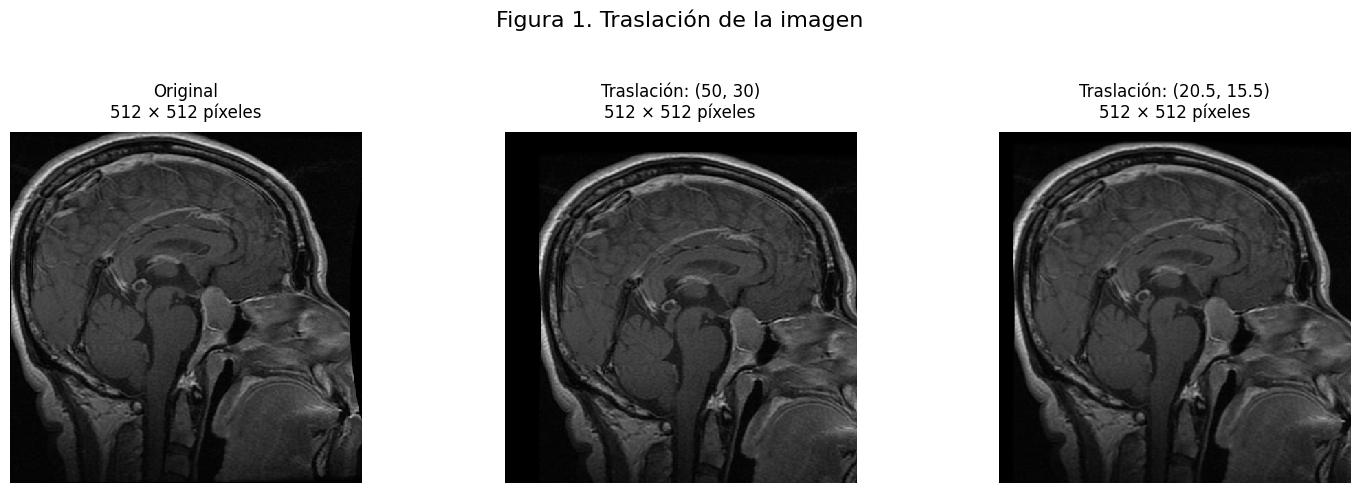

True

In [3]:
# Traslación de 50 píxeles en x y 30 en y
matriz_traslacion_entera = np.float32([
    [1, 0, 50],
    [0, 1, 30]
])

traslacion_entera = cv2.warpAffine(
    img_geometria,
    matriz_traslacion_entera,
    (ancho, alto),
    flags=cv2.INTER_LINEAR,
    borderMode=cv2.BORDER_CONSTANT,
    borderValue=0
)

# Traslación de 20.5 píxeles en x y 15.5 en y
matriz_traslacion_decimal = np.float32([
    [1, 0, 20.5],
    [0, 1, 15.5]
])

traslacion_decimal = cv2.warpAffine(
    img_geometria,
    matriz_traslacion_decimal,
    (ancho, alto),
    flags=cv2.INTER_LINEAR,
    borderMode=cv2.BORDER_CONSTANT,
    borderValue=0
)

mostrar_comparacion(
    imagenes=[
        img_geometria,
        traslacion_entera,
        traslacion_decimal
    ],
    titulos=[
        "Original",
        "Traslación: (50, 30)",
        "Traslación: (20.5, 15.5)"
    ],
    titulo_general="Figura 1. Traslación de la imagen",
    nombre_archivo="Figura_1_Traslacion.png"
)

cv2.imwrite(
    str(carpeta_resultados / "Traslacion_50_30.png"),
    traslacion_entera
)

cv2.imwrite(
    str(carpeta_resultados / "Traslacion_20_5_15_5.png"),
    traslacion_decimal
)

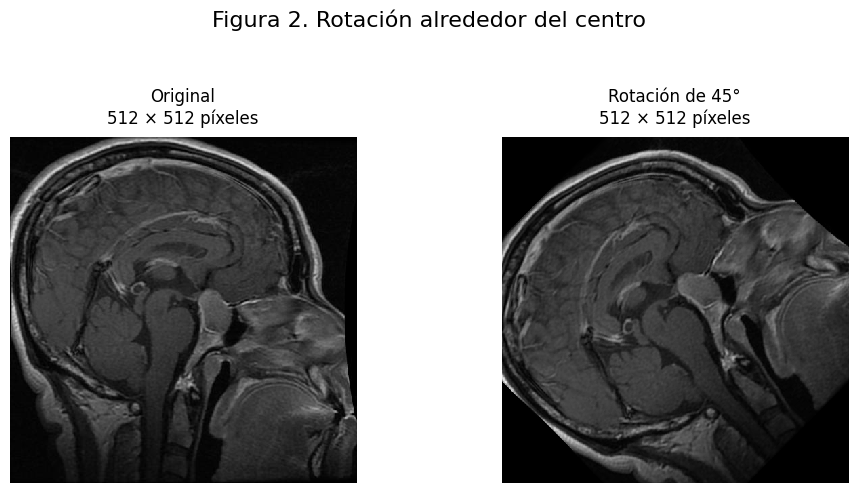

True

In [4]:
# Centro geométrico de la imagen
centro = (
    (ancho - 1) / 2,
    (alto - 1) / 2
)

# Matriz de rotación de 45 grados
matriz_rotacion = cv2.getRotationMatrix2D(
    centro,
    45,
    1.0
)

imagen_rotada = cv2.warpAffine(
    img_geometria,
    matriz_rotacion,
    (ancho, alto),
    flags=cv2.INTER_LINEAR,
    borderMode=cv2.BORDER_CONSTANT,
    borderValue=0
)

mostrar_comparacion(
    imagenes=[
        img_geometria,
        imagen_rotada
    ],
    titulos=[
        "Original",
        "Rotación de 45°"
    ],
    titulo_general="Figura 2. Rotación alrededor del centro",
    nombre_archivo="Figura_2_Rotacion.png"
)

cv2.imwrite(
    str(carpeta_resultados / "Rotacion_45_grados.png"),
    imagen_rotada
)

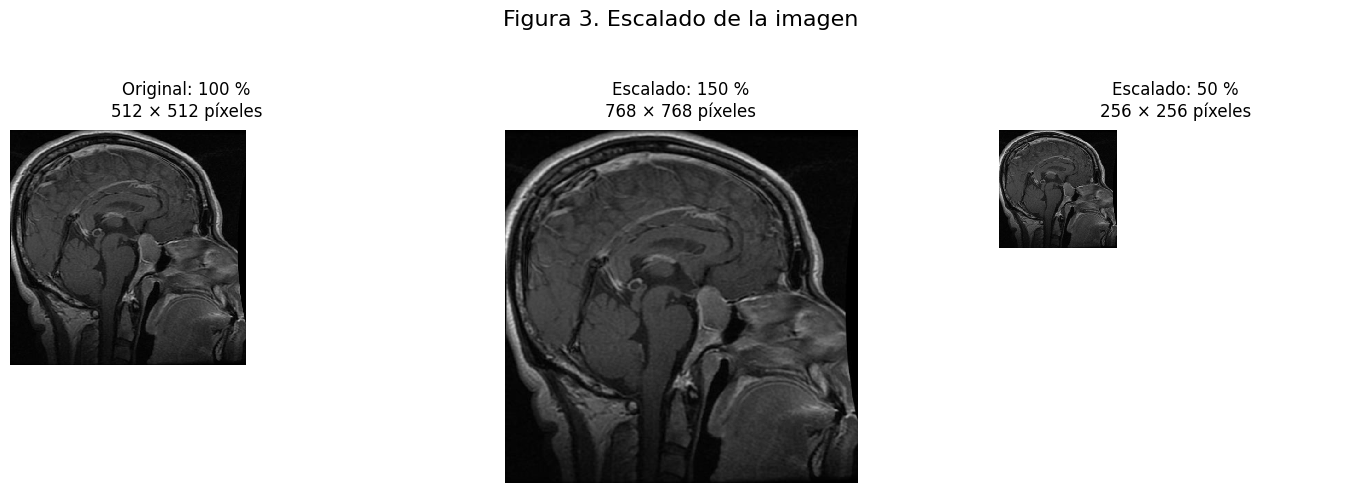

True

In [5]:
# Tamaños de las imágenes resultantes
tamano_150 = (
    max(1, round(ancho * 1.5)),
    max(1, round(alto * 1.5))
)

tamano_50 = (
    max(1, round(ancho * 0.5)),
    max(1, round(alto * 0.5))
)

imagen_150 = cv2.resize(
    img_geometria,
    tamano_150,
    interpolation=cv2.INTER_LINEAR
)

imagen_50 = cv2.resize(
    img_geometria,
    tamano_50,
    interpolation=cv2.INTER_AREA
)

mostrar_comparacion(
    imagenes=[
        img_geometria,
        imagen_150,
        imagen_50
    ],
    titulos=[
        "Original: 100 %",
        "Escalado: 150 %",
        "Escalado: 50 %"
    ],
    titulo_general="Figura 3. Escalado de la imagen",
    nombre_archivo="Figura_3_Escalado.png",
    escala_espacial_comun=True
)

cv2.imwrite(
    str(carpeta_resultados / "Escalado_150.png"),
    imagen_150
)

cv2.imwrite(
    str(carpeta_resultados / "Escalado_50.png"),
    imagen_50
)

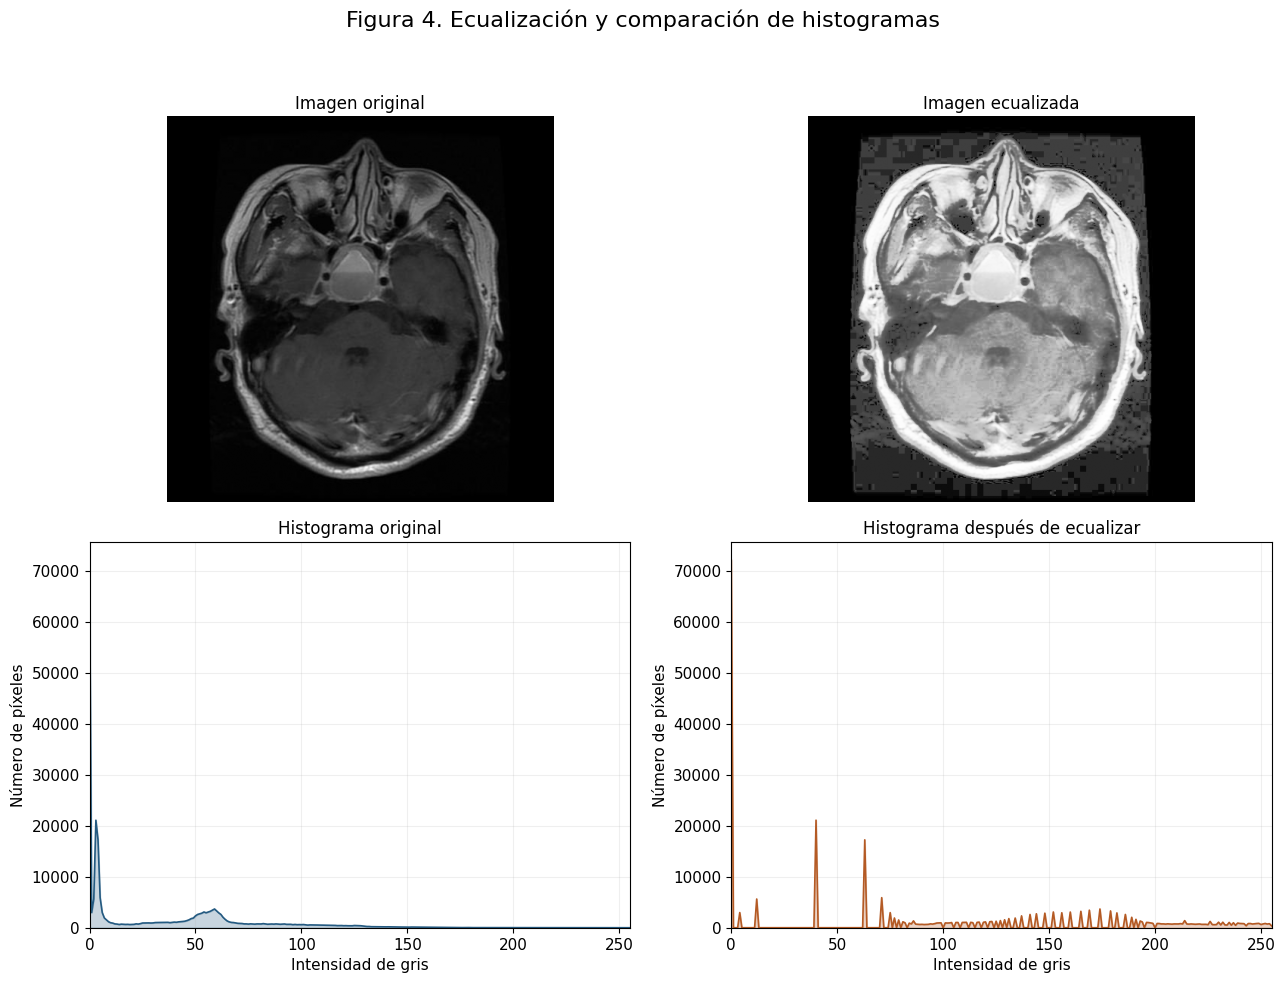

True

In [6]:
# Ecualización de la imagen en escala de grises
imagen_ecualizada = cv2.equalizeHist(img_histograma)

# Histogramas
hist_original = cv2.calcHist(
    [img_histograma],
    [0],
    None,
    [256],
    [0, 256]
).ravel()

hist_ecualizado = cv2.calcHist(
    [imagen_ecualizada],
    [0],
    None,
    [256],
    [0, 256]
).ravel()

niveles = np.arange(256)

# Mismo límite vertical para comparar ambos histogramas
limite_y = max(
    hist_original.max(),
    hist_ecualizado.max()
) * 1.05

fig, ejes = plt.subplots(
    2,
    2,
    figsize=(13, 10)
)

# Imágenes
ejes[0, 0].imshow(
    img_histograma,
    cmap="gray",
    vmin=0,
    vmax=255
)
ejes[0, 0].set_title("Imagen original")
ejes[0, 0].axis("off")

ejes[0, 1].imshow(
    imagen_ecualizada,
    cmap="gray",
    vmin=0,
    vmax=255
)
ejes[0, 1].set_title("Imagen ecualizada")
ejes[0, 1].axis("off")

# Histograma original
ejes[1, 0].plot(
    niveles,
    hist_original,
    color="#245a81",
    linewidth=1.2
)
ejes[1, 0].fill_between(
    niveles,
    hist_original,
    color="#245a81",
    alpha=0.25
)
ejes[1, 0].set_title("Histograma original")

# Histograma ecualizado
ejes[1, 1].plot(
    niveles,
    hist_ecualizado,
    color="#b45a24",
    linewidth=1.2
)
ejes[1, 1].fill_between(
    niveles,
    hist_ecualizado,
    color="#b45a24",
    alpha=0.25
)
ejes[1, 1].set_title("Histograma después de ecualizar")

for eje in ejes[1, :]:
    eje.set_xlabel("Intensidad de gris")
    eje.set_ylabel("Número de píxeles")
    eje.set_xlim(0, 255)
    eje.set_ylim(0, limite_y)
    eje.grid(alpha=0.2)

fig.suptitle(
    "Figura 4. Ecualización y comparación de histogramas",
    fontsize=16
)

fig.tight_layout(rect=[0, 0, 1, 0.95])

fig.savefig(
    carpeta_resultados / "Figura_4_Ecualizacion_Histogramas.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

cv2.imwrite(
    str(carpeta_resultados / "Imagen_1_ecualizada.png"),
    imagen_ecualizada
)